# Демо · Карты внимания

Лекция 2, слайд 24. Тезис: внимание это не метафора, доли считаются моделью, их можно вынуть и посмотреть.

Три шага:
1. На кого смотрит местоимение «его».
2. Чем заняты разные головы.
3. Сколько внимания достается инструкции из начала, когда контекст растет.

Модель та же, что на первой лекции: `Qwen3-0.6B-Base`, может работать на CPU. Карты внимания получаются только с `attn_implementation="eager"` и `output_attentions=True`. Картинки сохраняются в `fallback/`.

In [1]:
import os, re, json, math
from pathlib import Path
import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL = os.environ.get("LAB_MODEL", "Qwen/Qwen3-0.6B-Base")
HERE = Path.cwd()

FALLBACK = HERE / "fallback"
FALLBACK.mkdir(exist_ok=True)
ASSETS = HERE.parent.parent / "lectures" / "02" / "assets"

device = (
    "cuda" if torch.cuda.is_available() 
    else "mps" if torch.backends.mps.is_available() 
    else "cpu"
)
tok = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForCausalLM.from_pretrained(
    MODEL, 
    dtype=torch.float32, 
    attn_implementation="eager"
).to(device).eval()

print(MODEL, "на", device, "| слоев", model.config.num_hidden_layers, "| голов", model.config.num_attention_heads)

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans", 
        "axes.spines.top": False, 
        "axes.spines.right": False,
        "figure.dpi": 110, 
        "savefig.dpi": 150
    }
)
GRAY = "#333333"

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Qwen/Qwen3-0.6B-Base на mps | слоев 28 | голов 16


## Помощники

`tokenize_with_spans` возвращает id токенов и подписи к ним: подпись это кусок исходного текста, который токен покрывает, поэтому она читаема, даже если токен это половина буквы в байтах. `attentions` прогоняет модель и отдает карты по слоям, каждая `[heads, n, n]`: строка `i` это распределение внимания токена `i`, доли в сумме дают единицу.

In [2]:
def tokenize_with_spans(text):
    enc = tok(text, add_special_tokens=False, return_offsets_mapping=True)
    return (
        enc["input_ids"], 
        enc["offset_mapping"], 
        [text[s:e] for s, e in enc["offset_mapping"]]
    )

def attentions(ids):
    with torch.no_grad():
        out = (
            model(input_ids=torch.tensor([ids], device=device), 
            output_attentions=True)
        )
    return torch.stack([a[0].float().cpu() for a in out.attentions])

def span(offsets, text, word):
    start = text.find(word)
    end = start + len(word)
    return [i for i, (s, e) in enumerate(offsets) if e > start and s < end]

def bars(ax, labels, weights, title):
    ax.bar(range(len(labels)), weights, color=GRAY)
    ax.set_xticks(range(len(labels))) 
    ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=11)

def heat(ax, labels, a, title):
    ax.imshow(a, cmap="Greys", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=7)
    ax.set_title(title, fontsize=10)
    for s in ("top", "right"): ax.spines[s].set_visible(True)

## 1. На кого смотрит «его»

Предложение с местоимением, у которого два кандидата: врач и пациент. Для человека ответ очевиден. Берем строку внимания последнего токена местоимения в каждом слое и каждой голове и ищем голову, в которой больше всего доли приходится на токены слова «пациента». Модель никто не учил разрешать местоимения, это побочный результат предсказания следующего слова.

лучшая голова: слой 3, голова 3, на «пациента» 0.73, на «Врач» 0.15
еще четыре: [(6, 0, 0.7), (6, 1, 0.7), (11, 1, 0.43), (16, 13, 0.41)]


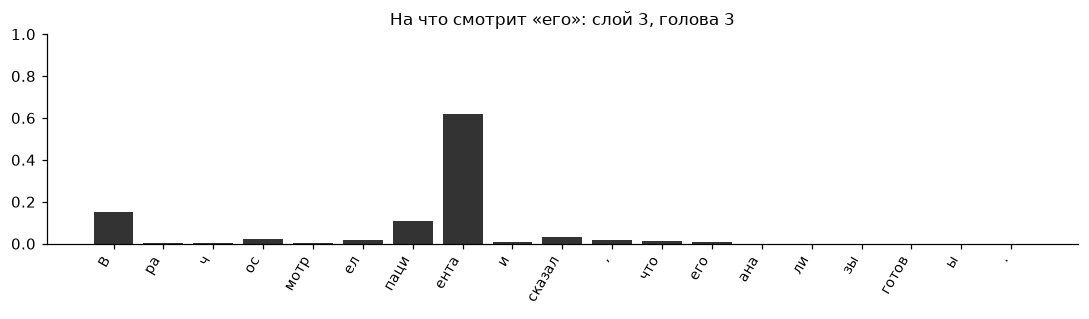

In [12]:
SENT = "Врач осмотрел пациента и сказал, что его анализы готовы."
ids, offsets, labels = tokenize_with_spans(SENT)
attn = attentions(ids)
p = span(offsets, SENT, "его")
a = span(offsets, SENT, "пациента")
d = span(offsets, SENT, "Врач")
rows = attn[:, :, p[-1], :]            
on_patient = rows[:, :, a].sum(-1)
on_doctor = rows[:, :, d].sum(-1)
L, H = divmod(int(on_patient.argmax()), rows.shape[1])

print(f"лучшая голова: слой {L}, голова {H}, на «пациента» {on_patient[L, H]:.2f}, на «Врач» {on_doctor[L, H]:.2f}")

top = torch.topk(on_patient.flatten(), 5).indices.tolist()
print(
    "еще четыре:", 
    [
        (
            i // rows.shape[1], 
            i % rows.shape[1], 
            round(float(on_patient.flatten()[i]), 2)
        ) 
        for i in top[1:]
    ]
)

fig, ax = plt.subplots(figsize=(10, 3))
bars(
    ax, 
    labels, 
    rows[L, H].tolist(), 
    f"На что смотрит «его»: слой {L}, голова {H}"
)
fig.tight_layout(); fig.savefig(FALLBACK / "01_pronoun.png"); plt.show()

Для сравнения: среднее по всем головам всех слоев. Без выбора головы картина размазана, и большая доля уходит на первый токен. Это сток, о нем в шаге 3.

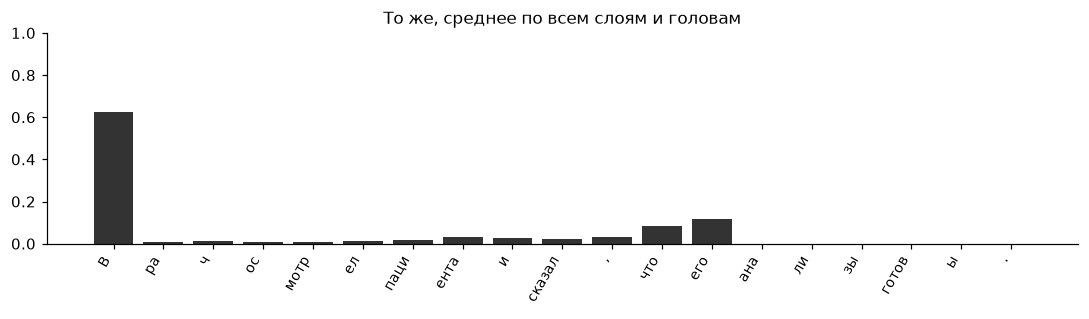

In [4]:
fig, ax = plt.subplots(figsize=(10, 3))
bars(
    ax, 
    labels, 
    rows.mean((0, 1)).tolist(), 
    "То же, среднее по всем слоям и головам"
)
fig.tight_layout()
plt.show()

## 2. Чем заняты головы

Текст с повторами. Для каждой головы считаем три числа: сколько внимания в среднем уходит на предыдущий токен, на первый токен и на более раннее вхождение того же токена. Берем по лучшей голове на каждый признак и рисуем ее карту целиком: строка это токен, который смотрит, столбец это токен, на который смотрят. Четвертая карта это голова из шага 1. Специализацию никто не задавал, она выучилась сама.

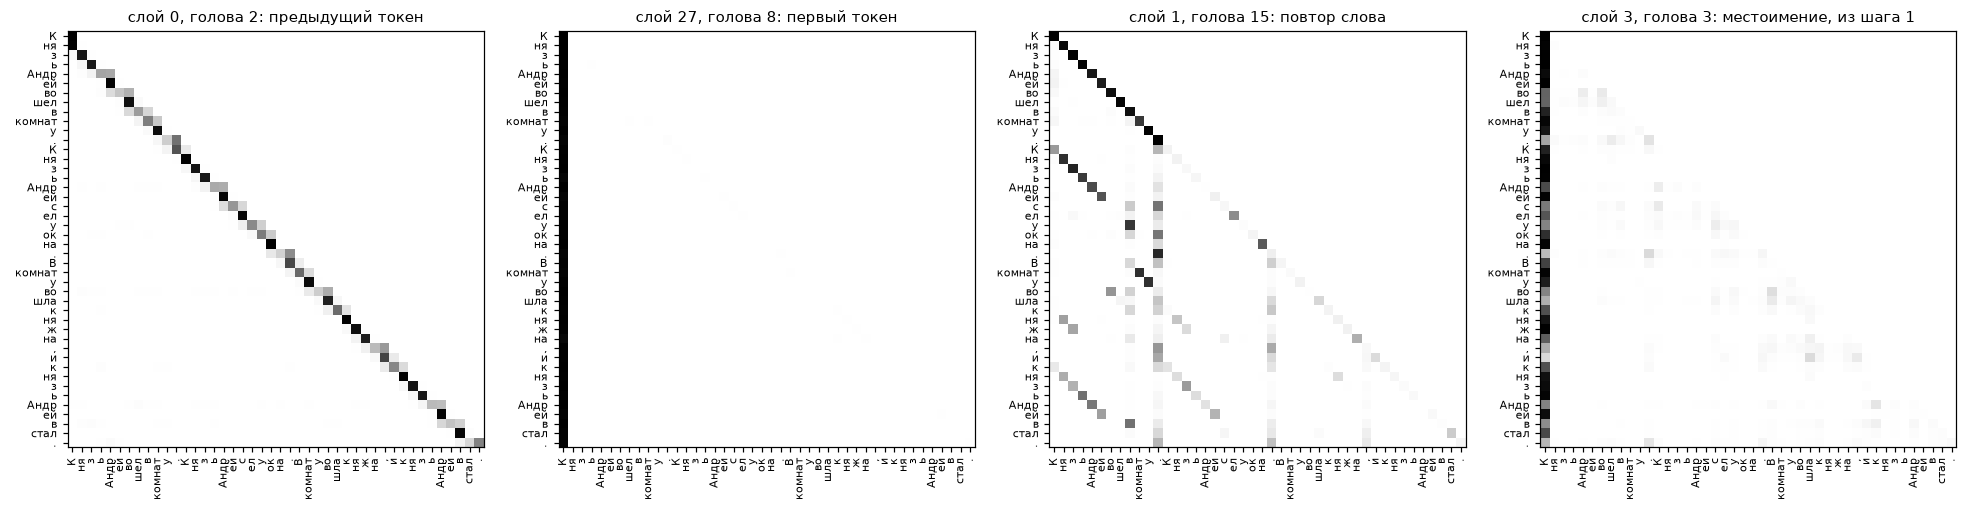

In [5]:
TEXT = "Князь Андрей вошел в комнату. Князь Андрей сел у окна. В комнату вошла княжна, и князь Андрей встал."
ids2, offsets2, labels2 = tokenize_with_spans(TEXT)
attn2 = attentions(ids2)
n = len(ids2)
# доля на предыдущий токен
prev = attn2[:, :, 1:, :-1].diagonal(dim1=-2, dim2=-1).mean(-1) 
# доля на первый токен
first = attn2[:, :, 1:, 0].mean(-1)                                       
rep = torch.zeros(attn2.shape[:2])
pairs = [(i, j) for i in range(n) for j in range(i - 1) if ids2[i] == ids2[j]]
for i, j in pairs:
    rep += attn2[:, :, i, j]
rep /= max(len(pairs), 1)

def best(score):
    k = int(score.argmax())
    return k // score.shape[1], k % score.shape[1]

picks = [
    (*best(prev), "предыдущий токен"), 
    (*best(first), "первый токен"), 
    (*best(rep), "повтор слова"), 
    (L, H, "местоимение, из шага 1")
]
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (l, h, what) in zip(axes, picks):
    heat(ax, labels2, attn2[l, h].numpy(), f"слой {l}, голова {h}: {what}")
fig.tight_layout()
fig.savefig(FALLBACK / "02_heads.png")
plt.show()

## 3. Размывание

Инструкция в начале, за ней текст из корпуса такой длины, чтобы весь вход был 128, 512 и 1024 токена. Смотрим, какая доля внимания последнего токена приходится на токены инструкции, в среднем по всем слоям и головам, и сравниваем с долей при равномерном внимании.

Первый токен входа это сток: на него модель сбрасывает около половины внимания при любом тексте. Он не инструкция и не смысл, поэтому считается отдельно и в долю на инструкцию не входит. Инструкция никуда не делась, она в контексте. Но доли в сумме дают единицу, токенов становится больше, и ей достается все меньше.

Текст-наполнитель это «Война и мир», тот же корпус, что в лабораторной.

n=  128: на инструкцию 0.0213 (равномерно было бы 0.1797), на сток 0.489
n=  512: на инструкцию 0.0094 (равномерно было бы 0.0449), на сток 0.451
n= 1024: на инструкцию 0.0027 (равномерно было бы 0.0225), на сток 0.411


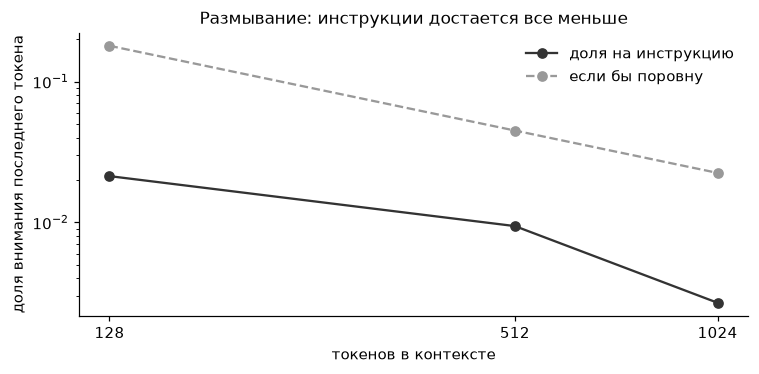

In [6]:
INSTRUCTION = "Отвечай только по-русски и в конце каждого ответа ставь слово КОНЕЦ."
CORPUS_URL = "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"
corpus = Path(os.environ.get("LAB_CORPUS", HERE / "corpus.txt"))
if not corpus.exists():
    import urllib.request; urllib.request.urlretrieve(CORPUS_URL, corpus)
words = re.findall(
    r"[а-я]+(?:-[а-я]+)*", 
    corpus.read_text(encoding="utf-8").lower().replace("ё", "е")
)[20000:30000]

filler = " ".join(words)
prefix = tok(INSTRUCTION + "\n", add_special_tokens=False)["input_ids"]
filler_ids = tok(filler, add_special_tokens=False)["input_ids"]

rows_d = []
for n_ctx in (128, 512, 1024):
    ids3 = prefix + filler_ids[: n_ctx - len(prefix)]
    att = attentions(ids3)
    # строка последнего токена, среднее по слоям и головам
    row = att[:, :, -1, :].mean((0, 1))                 
    share = float(row[1:len(prefix)].sum())
    sink = float(row[0]); uniform = (len(prefix) - 1) / len(ids3)
    rows_d.append((len(ids3), share, uniform, sink))
    print(f"n={len(ids3):5d}: на инструкцию {share:.4f} (равномерно было бы {uniform:.4f}), на сток {sink:.3f}")
    del att

xs = [r[0] for r in rows_d]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(xs, [r[1] for r in rows_d], "o-", color=GRAY, label="доля на инструкцию")
ax.plot(xs, [r[2] for r in rows_d], "o--", color="#999999", label="если бы поровну")
ax.set_xscale("log", base=2)
ax.set_yscale("log"); ax.set_xticks(xs); ax.set_xticklabels(xs)
ax.set_xlabel("токенов в контексте")
ax.set_ylabel("доля внимания последнего токена")
ax.legend(frameon=False)
ax.set_title("Размывание: инструкции достается все меньше", fontsize=11)
fig.tight_layout()
fig.savefig(FALLBACK / "03_dilution.png")
plt.show()